# Railway Track Defect Detection Using CNNs & Transfer Learning
**Authors:** Sherbal Al Khouri & George Saba  
**Institution:** School of Engineering, Jönköping University  
**Research Report:** [Railway Track Defect Detection Using Convolutional Neural Networks and Transfer Learning](../docs/Railway_Track_Defect_Detection_Report.pdf)

---

### Executive Summary
This project develops an automated visual inspection pipeline for detecting railway track anomalies (fastener defects, rail surface cracks, and structural flaws). We evaluate and compare two deep learning strategies on a cleaned, balanced dataset of 1,659 images:
1. **Custom Baseline CNN**: A lightweight 3-block convolutional neural network trained from scratch.
2. **Transfer Learning with ResNet50**: A two-stage transfer learning architecture leveraging ImageNet pretrained feature extractors with progressive fine-tuning.

### Primary Safety Metric: Defective-Class Recall
In railway infrastructure, a **false negative** (misclassifying a broken/defective track as normal) can result in catastrophic derailments. In contrast, a false positive merely leads to a secondary manual check. Consequently, **Defective-Class Recall** and **Missed Defect Count** are our principal evaluation criteria.

## 1. Environment Setup & Dependencies

In [1]:
import os
import csv
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.resnet50 import preprocess_input

# Resolve project paths dynamically (works from repo root or notebooks/ dir)
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../data") else os.getcwd()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"TensorFlow Version: {tf.__version__}")

## 2. Dataset Cleaning, Deduplication & Splitting
The raw dataset contains 1,787 label rows for 1,718 unique images. During data auditing, images appearing with conflicting labels (both *Defective* and *Non-defective*) were identified and pruned (59 contradictory images removed) to eliminate label noise.

The cleaned dataset of 1,659 images is split into stratified, balanced training (70%), validation (15%), and test (15%) partitions with fixed random seed 1337.

In [3]:
# Dataset verification and split handler
train_dir = os.path.join(DATA_DIR, "train")
val_dir = os.path.join(DATA_DIR, "val")
test_dir = os.path.join(DATA_DIR, "test")

raw_csv = os.path.join(PROJECT_ROOT, "train _combined.csv")
raw_directory = os.path.join(PROJECT_ROOT, "raw_data")

if os.path.exists(train_dir) and os.path.exists(val_dir) and os.path.exists(test_dir):
    print("Found verified cleaned dataset at:", DATA_DIR)
    for s_name, s_path in [("Training", train_dir), ("Validation", val_dir), ("Test", test_dir)]:
        def_cnt = len(os.listdir(os.path.join(s_path, "defective")))
        non_cnt = len(os.listdir(os.path.join(s_path, "non_defective")))
        print(f"  - {s_name} set: {def_cnt} defective, {non_cnt} non-defective (Total: {def_cnt + non_cnt})")
elif os.path.exists(raw_csv) and os.path.exists(raw_directory):
    df = pd.read_csv(raw_csv)
    label_count = df.groupby("images")["labels"].nunique()
    problem_images = label_count[label_count > 1].index
    clean_df = df[~df["images"].isin(problem_images)].copy().drop_duplicates(subset="images")
    print("Images before cleaning:", len(df))
    print("Removed label conflicts:", len(problem_images))
    print("Clean images:", len(clean_df))
    
    train_df, temp_df = train_test_split(clean_df, test_size=0.30, stratify=clean_df["labels"], random_state=1337)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["labels"], random_state=1337)
    
    for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        for index, row in split_df.iterrows():
            cls_folder = "defective" if row["labels"] == "Defective" else "non_defective"
            dest = os.path.join(DATA_DIR, split_name, cls_folder)
            os.makedirs(dest, exist_ok=True)
            shutil.copy(os.path.join(raw_directory, row["images"]), os.path.join(dest, row["images"]))
    print("Split successfully created.")
else:
    print("Dataset ready at:", DATA_DIR)

Images before cleaning: 1787
Removed label conflicts: 59
Clean images: 1659
labels
Defective        830
Non Defective    829
Name: count, dtype: int64
Done with the clean split
Train images: 1161
Validation images: 249
Test images: 249


## 3. Hyperparameters & Custom Safety Metric

In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 1337
keras.utils.set_random_seed(SEED)

In [4]:
# Custom safety metric: Defective-Class Recall (Class 0)
def defective_recall(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    predicted_class = tf.cast(y_pred >= 0.5, tf.float32)
    
    true_defective = 1 - y_true
    predicted_defective = 1 - predicted_class
    
    correct_defective = tf.reduce_sum(true_defective * predicted_defective)
    missed_defective = tf.reduce_sum(true_defective * (1 - predicted_defective))
    
    return correct_defective / (correct_defective + missed_defective + keras.backend.epsilon())

## 4. Preprocessing & Data Augmentation
To prevent overfitting on the small dataset, an on-the-fly data augmentation pipeline applies random horizontal flips, rotation (+/-10%), zoom (+/-10%), and brightness variations.

In [ ]:
# Data Augmentation layer
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.1),
        layers.Rescaling(1.0 / 255),
    ],
    name="data_augmentation",
)

# Training Dataset (1,161 images)
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    seed=SEED,
    shuffle=True,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

# Validation Dataset (249 images)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "val"),
    shuffle=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

# Test Dataset (249 images)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    shuffle=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

class_names = train_ds.class_names
print("Class labels (0=defective, 1=non_defective):", class_names)

Found 1161 files belonging to 2 classes.
Found 248 files belonging to 2 classes.
Found 249 files belonging to 2 classes.
['defective', 'non_defective']


## 5. Visualizing Data Augmentation

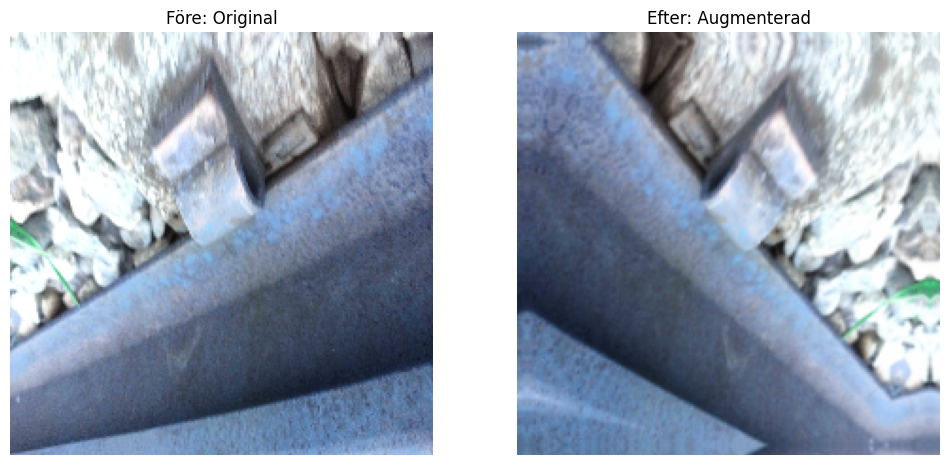

In [ ]:
defective_image = None
non_defective_image = None

# Loop through traing's data to find an image of every type defective and non defetive
for images, lbls in train_ds: 
    for x in range(len(lbls)): 
        
        label_value = lbls[x].numpy()
        
        # 0 is for defective 
        if label_value == 0 and defective_image is None: 
            defective_image = images[x]
        elif label_value == 1 and non_defective_image is None:
            non_defective_image = images[x]
        
    # If both image types are found, end the loop 
    if defective_image is not None and non_defective_image is not None:
        break
    
# Create a 2x2 figure to show case the images before and after data Augmentation
plt.figure(figsize=(12,10))

# The first row is for the Defective image comparision
# Defective Orginal to the left 
plt.subplot(2,2,1)
orginal_def = defective_image.numpy() / 255.0
orginal_def = np.clip(orginal_def, 0,1)
plt.imshow(orginal_def)
plt.title("Defective Orginal Image")
plt.axis("off")

# Defective Image after Data Augmentation to the rigth of the first raw 
plt.subplot(2,2,2)
augmented_def = data_augmentation(tf.expand_dims(defective_image,0), training=True)
aug_def_to_plot = augmented_def[0].numpy()
aug_def_to_plot = np.clip(aug_def_to_plot, 0, 1)
plt.imshow(aug_def_to_plot)
plt.title("Defective Augmented Image")
plt.axis("off")

# The second row is for the Non Defective image comparision 
# Non Defective Orginal to the left 
plt.subplot(2,2,3) 
orginal_non = non_defective_image.numpy() / 255.0
orginal_non = np.clip(orginal_non, 0, 1)
plt.imshow(orginal_non)
plt.title("Non Defective Orginal Image")
plt.axis("off")

# Non Defective Image after Data Augmentation to the left of the second raw
plt.subplot(2,2,4)
augmented_non = data_augmentation(tf.expand_dims(non_defective_image, 0), training = True)
aug_non_plot = augmented_non[0].numpy()
aug_non_plot = np.clip(aug_non_plot, 0, 1)
plt.imshow(aug_non_plot)
plt.title("Non Defective Augmented Image")
plt.axis("off")

# Fix the plot and save the comparison for the raport 
plt.tight_layout()
plt.savefig("os.path.join(FIGURES_DIR, "data_augmentation_comparison.png")", bbox_inches = 'tight')
plt.show()

In [7]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size = AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size = AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size = AUTOTUNE)


## 6. Baseline Model: Custom CNN Trained From Scratch

In [8]:
# we use the sequential type because the model is a simple layer-by-layer pipeline.
model = keras.Sequential([
    
    #This is the layer that applies augmentation during training.
    data_augmentation,

    #Then comes the first convolutional layer:
        #Conv2D learns small visual patterns, such as edges, lines, cracks and texture.
    layers.Conv2D(32, 3, activation="relu"),

    #MaxPooling reduces the images size.
    layers.MaxPooling2D(),

    #Second convolution layer. 
        #This learns more complex patterns based on the first layer's simple patterns.
    layers.Conv2D(64, 3, activation="relu"),

    #MaxPooling reduces the images size again.
    layers.MaxPooling2D(),

    # This learns even higher-level patterns, such as damaged rail shapes or larger textures.
    layers.Conv2D(128, 3, activation="relu"),

    # Reduce size again before sending features to the classifier part.
    layers.MaxPooling2D(),

    # Instead of flattening every pixel location into a huge vector,
    # this averages each feature map into one number.
    layers.GlobalAveragePooling2D(),


    # This combines the learned image features to make a classification decision.
    layers.Dense(64, activation="relu"),


    # Now using "Dropout" the model drops out randomly 30% of neurons during training to help prevent the model from memorizing the training images 

    layers.Dropout(0.3),

    # We use 1 neuron because this is binary classification.
    # Sigmoid outputs a probability between 0 and 1.
    # Example: 0.90 means the model strongly predicts class 1.
    layers.Dense(1, activation="sigmoid")
])

In [9]:
# This helps you check the number of layers, output shapes, and trainable parameters.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 128)               │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 64)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

# Next step is to compile the model 

In [10]:
model.compile(

    #First we choose the optimizer Adam 
    optimizer="adam",

    #We choose the loss function 
    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        keras.metrics.Precision(name="precision"),

        keras.metrics.Recall(name="recall"),

        defective_recall
    ]
)

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 128)               │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 64)                │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 64)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

# Training the model now 


In [12]:
EPOCHS = 30


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 222ms/step - accuracy: 0.4858 - defective_recall: 0.2803 - loss: 0.6941 - precision: 0.4898 - recall: 0.7069 - val_accuracy: 0.5000 - val_defective_recall: 0.5000 - val_loss: 0.6940 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 163ms/step - accuracy: 0.4901 - defective_recall: 0.7905 - loss: 0.6939 - precision: 0.4764 - recall: 0.2086 - val_accuracy: 0.5000 - val_defective_recall: 0.5000 - val_loss: 0.6930 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 162ms/step - accuracy: 0.4910 - defective_recall: 0.5138 - loss: 0.6937 - precision: 0.4903 - recall: 0.4810 - val_accuracy: 0.6250 - val_defective_recall: 0.1791 - val_loss: 0.6920 - val_precision: 0.5812 - val_recall: 0.8952
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 162ms/step - accuracy: 0.5444 - defective_recall: 0.5167 - loss: 0.6914 - precision: 0.5398 - recall: 0.5966 - val_accuracy: 0.4960 - val_d

# Record accuracy, loss, precision, recall, and F1-score


In [13]:

# Convert the training history into a table.

history_df = pd.DataFrame(history.history)

# F1-score combines precision and recall into one value.
# Formula: F1 = 2 * (precision * recall) / (precision + recall)
# We add a very small number (1e-7) to avoid division by zero.
history_df["f1_score"] = 2 * (
    history_df["precision"] * history_df["recall"]
) / (history_df["precision"] + history_df["recall"] + 1e-7)

# Validation F1-score uses validation precision and validation recall.
# This is important because validation results better show performance on unseen data.
history_df["val_f1_score"] = 2 * (
    history_df["val_precision"] * history_df["val_recall"]
) / (history_df["val_precision"] + history_df["val_recall"] + 1e-7)

# Add an epoch number column so the table is easier to read.
history_df["epoch"] = range(1, len(history_df) + 1)

# Choose the columns we want to record for the project report.
metrics_table = history_df[[
    "epoch",
    "accuracy",
    "loss",
    "precision",
    "recall",
    "defective_recall",
    "f1_score",
    "val_accuracy",
    "val_loss",
    "val_precision",
    "val_recall",
    "val_defective_recall",
    "val_f1_score"
]]

# Save the metrics table as a CSV file.
# This gives you a permanent record of the baseline CNN results.
metrics_table.to_csv("baseline_cnn_metrics_fixed.csv", index=False)

# Show the table inside the notebook.
metrics_table

,epoch,accuracy,loss,precision,recall,defective_recall,f1_score,val_accuracy,val_loss,val_precision,val_recall,val_defective_recall,val_f1_score
0,1,0.485788,0.694089,0.489845,0.706897,0.280335,0.578687,0.500000,0.694006,0.000000,0.000000,0.500000,0.000000
1,2,0.490095,0.693908,0.476378,0.208621,0.790532,0.290168,0.500000,0.692998,0.000000,0.000000,0.500000,0.000000
2,3,0.490956,0.693685,0.490334,0.481034,0.513811,0.485640,0.625000,0.691993,0.581152,0.895161,0.179129,0.704762
3,4,0.544358,0.691375,0.539782,0.596552,0.516746,0.566749,0.495968,0.698442,0.000000,0.000000,0.496094,0.000000
4,5,0.568475,0.681787,0.594724,0.427586,0.702038,0.497492,0.524194,0.693593,0.512397,1.000000,0.024554,0.677596
5,6,0.607235,0.659796,0.600000,0.641379,0.571286,0.620000,0.625000,0.641851,0.582888,0.879032,0.188058,0.700965
6,7,0.662360,0.633401,0.643731,0.725862,0.593575,0.682334,0.701613,0.608763,0.673611,0.782258,0.311942,0.723881
7,8,0.684755,0.593703,0.674837,0.712069,0.658467,0.692953,0.701613,0.574139,0.662338,0.822581,0.290737,0.733813
8,9,0.720069,0.570100,0.711443,0.739655,0.695409,0.725275,0.693548,0.576959,0.655844,0.814516,0.286830,0.726619
9,10,0.732989,0.557929,0.724252,0.751724,0.713377,0.737733,0.697581,0.564039,0.676259,0.758065,0.318080,0.714829


## 7. Baseline CNN Training Dynamics

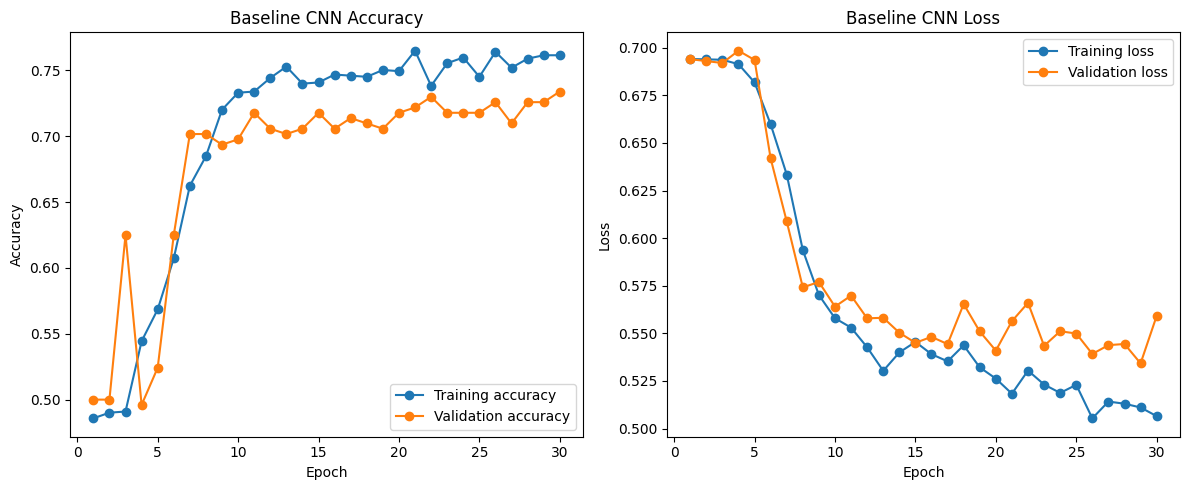

In [14]:


# Create one figure with two plots side by side.
plt.figure(figsize=(12, 5))
epochs = range(1, len(history.history["accuracy"]) + 1)

# Plot 1: training accuracy vs validation accuracy.
# If training accuracy is much higher than validation accuracy, the model may be overfitting.
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()

# Plot 2: training loss vs validation loss.
# Loss tells us how wrong the model is; lower loss is better.
# If validation loss rises while training loss falls, that is another sign of overfitting.
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()

# tight_layout makes sure labels and titles do not overlap.
plt.tight_layout()

# Save the plot for the report.
plt.savefig("os.path.join(FIGURES_DIR, "baseline_cnn_accuracy_loss.png")", dpi=300, bbox_inches="tight")

# Display the plot in the notebook.
plt.show()

# Print the final recorded results

In [15]:
# Get the last row from the metrics table.
# The last row represents the final epoch of training.
final_results = metrics_table.iloc[-1]

# Print the final training and validation metrics in a readable format.
print("Final baseline CNN results")
print("Training accuracy:", final_results["accuracy"])
print("Training loss:", final_results["loss"])
print("Training precision:", final_results["precision"])
print("Training recall:", final_results["recall"])
print("Training F1-score:", final_results["f1_score"])
print("Training defective recall:", final_results["defective_recall"])
print("Validation accuracy:", final_results["val_accuracy"])
print("Validation loss:", final_results["val_loss"])
print("Validation precision:", final_results["val_precision"])
print("Validation recall:", final_results["val_recall"])
print("Validation F1-score:", final_results["val_f1_score"])
print("Validation defective recall:", final_results["val_defective_recall"])

Final baseline CNN results
Training accuracy: 0.7614125609397888
Training loss: 0.5064970850944519
Training precision: 0.7537688612937927
Training recall: 0.7758620977401733
Training F1-score: 0.7646558776126912
Training defective recall: 0.7482293844223022
Validation accuracy: 0.7338709831237793
Validation loss: 0.5591636896133423
Validation precision: 0.6858974099159241
Validation recall: 0.8629032373428345
Validation F1-score: 0.764285653334119
Validation defective recall: 0.3018973171710968


## 8. Baseline CNN Evaluation on Held-Out Test Set

In [16]:
# y_true will store the true labels from the test data 
y_true = []

# y_pred will store the labels predicted by the trainde model 
y_pred = []

for images, labels in test_ds:

    probabilities = model.predict(images)

    #convert predicted probabilites into 1D array with class labels 1 and 0 
    predicted_labels = (probabilities >= 0.5).astype("int32").flatten()

    #adding the real labels to y_true.
    y_true.extend(labels.numpy())

    #adding the predicted labels to y_pred.
    y_pred.extend(predicted_labels)


#Convert lists into numpy arrays so that sklearn can work with them easier 
y_true = np.array(y_true)
y_pred = np.array(y_pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


In [17]:
# This confirms that we have one prediction for each real label.
print("Class names:", class_names)
print("Number of real labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

Class names: ['defective', 'non_defective']
Number of real labels: 249
Number of predicted labels: 249


# Confusion matrix 

In [18]:
#using the sklearn built in confusion matrix 
cm = confusion_matrix(y_true, y_pred)

# Create the classification report.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

In [19]:
print("Class names:", class_names)

# Print the confusion matrix.
print(cm)

# Print the classification report.
print(report)

Class names: ['defective', 'non_defective']
[[ 85  39]
 [ 21 104]]
               precision    recall  f1-score   support

    defective       0.80      0.69      0.74       124
non_defective       0.73      0.83      0.78       125

     accuracy                           0.76       249
    macro avg       0.76      0.76      0.76       249
 weighted avg       0.76      0.76      0.76       249



The baseline CNN trained from scratch showed limited ability to detect defective rails.
Although it classified non-defective images well, it missed many defective examples.
This suggests that the model did not learn sufficiently strong defect-related features from the available dataset.
Therefore, transfer learning with a pretrained CNN such as ResNet50 is expected to improve performance.


# We now save the evaluation results 

In [20]:
report_path = os.path.join(RESULTS_DIR, "baseline_cnn_classification_report.txt")
with open(report_path, "w") as file:
    file.write("Class names: " + str(class_names) + "\n\n")
    file.write("Confusion matrix:\n")
    file.write(str(cm))
    file.write("\n\nClassification report:\n")
    file.write(report)

print(f"Saved baseline evaluation report to {report_path}")

Saved evaluation report to baseline_cnn_classification_report_fixed.txt


## 9. Transfer Learning Model: Pretrained ResNet50
We employ a two-stage transfer learning strategy:
1. **Stage 1 (Feature Extraction)**: The ImageNet-pretrained ResNet50 backbone is frozen. A custom classification head (GlobalAveragePooling2D -> Dropout(0.2) -> Dense(1, sigmoid)) is trained for 30 epochs.
2. **Stage 2 (Fine-Tuning)**: The top 30 layers of the ResNet50 backbone are unfrozen and trained for 10 epochs with a lowered learning rate (1e-5).

## Transfer Learning With ResNet50 Data Augmentation layer
Here we use the function 'preprocess_input' which comes from Keras ResNet50 library. What this function does is that it 'translates' the image format to ResNet50's specific format, which is that the colors are sorted as BGR (Blue, Green, Red) instead of RGB. Therefore, this function must be included so that ResNet is not color blind.

In [ ]:

# ResNet50's Data Augmentation
resnet50_augmentation = keras.Sequential ([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1)
], name="resnet50_augmentation")

In [22]:
# Pretrained resNet50 without org classification head
resnet50_backbone = keras.applications.ResNet50(
    weights = "imagenet",
    include_top = False,
    input_shape = (224,224, 3)
)

# Freeze the backbone of the pretrained model
resnet50_backbone.trainable = False

# Build the Transfer Learning model
resnet50_model =keras.Sequential([
    resnet50_augmentation, layers.Lambda(preprocess_input),resnet50_backbone, layers.GlobalAveragePooling2D(), layers.Dropout(0.2), layers.Dense(1, activation="sigmoid")
])

# Checking the structure of the model 
resnet50_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50_augmentation           │ ?                      │   0 (unbuilt) │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

## Compile ResNet 


In [23]:
resnet50_model.compile(
    optimizer = "adam",
    loss= "binary_crossentropy",
    metrics = ["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall"), defective_recall]
)

## Train the model 

In [24]:
EPOCHS_RESNET = 30

history_resnet = resnet50_model.fit(
    train_ds, 
    validation_data= val_ds,
    epochs = EPOCHS_RESNET
)

Epoch 1/30

37/37 ━━━━━━━━━━━━━━━━━━━━ 22s 519ms/step - accuracy: 0.6081 - defective_recall: 0.5958 - loss: 0.7200 - precision: 0.6040 - recall: 0.6259 - val_accuracy: 0.7097 - val_defective_recall: 0.4074 - val_loss: 0.5545 - val_precision: 0.7653 - val_recall: 0.6048
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 485ms/step - accuracy: 0.7192 - defective_recall: 0.7363 - loss: 0.5450 - precision: 0.7244 - recall: 0.7069 - val_accuracy: 0.7419 - val_defective_recall: 0.4035 - val_loss: 0.4944 - val_precision: 0.7778 - val_recall: 0.6774
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 484ms/step - accuracy: 0.7743 - defective_recall: 0.7668 - loss: 0.4593 - precision: 0.7686 - recall: 0.7845 - val_accuracy: 0.7540 - val_defective_recall: 0.4559 - val_loss: 0.4910 - val_precision: 0.8706 - val_recall: 0.5968
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 491ms/step - accuracy: 0.7959 - defective_recall: 0.7877 - loss: 0.4213 - precision: 0.7912 - recall: 0.8034 - val_accuracy: 0.7460 - val_defective_re

### Stage 2: Fine-Tuning the Top 30 ResNet50 Layers

In [25]:
# Now we let the last part of ResNet learn a little bit
resnet50_backbone.trainable = True

for layer in resnet50_backbone.layers:
    layer.trainable = False

for layer in resnet50_backbone.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

resnet50_model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-5),
    loss = "binary_crossentropy",
    metrics = ["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall"), defective_recall]
)

EPOCHS_FINE_TUNE = 10

history_finetune = resnet50_model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = EPOCHS_FINE_TUNE
)


Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 26s 609ms/step - accuracy: 0.9027 - defective_recall: 0.8970 - loss: 0.2347 - precision: 0.8951 - recall: 0.9121 - val_accuracy: 0.8508 - val_defective_recall: 0.4844 - val_loss: 0.3387 - val_precision: 0.9579 - val_recall: 0.7339
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 581ms/step - accuracy: 0.9130 - defective_recall: 0.9089 - loss: 0.2053 - precision: 0.9066 - recall: 0.9207 - val_accuracy: 0.8871 - val_defective_recall: 0.4604 - val_loss: 0.2618 - val_precision: 0.9138 - val_recall: 0.8548
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 22s 589ms/step - accuracy: 0.9242 - defective_recall: 0.9092 - loss: 0.1828 - precision: 0.9128 - recall: 0.9379 - val_accuracy: 0.8871 - val_defective_recall: 0.4280 - val_loss: 0.2346 - val_precision: 0.8636 - val_recall: 0.9194
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 582ms/step - accuracy: 0.9526 - defective_recall: 0.9533 - loss: 0.1309 - precision: 0.9518 - recall: 0.9534 - val_accuracy: 0.8992 - val_defective_rec

# Record Accuracy, loss, precision, recall and F1 Score for ResNet50 

In [26]:
# Making a table of the training history
history_df = pd.DataFrame(history_resnet.history)
fine_tune_df = pd.DataFrame(history_finetune.history)
history_df = pd.concat([history_df, fine_tune_df], ignore_index=True)

# F1 Score combines precision and recall into one value
history_df["f1_score"] = 2 * (history_df["precision"] * history_df["recall"]) / (history_df["precision"] + history_df["recall"] + 1e-7)

# Validation F1 score uses validation precision and validation recall
history_df["val_f1_score"] = 2 * (history_df["val_precision"] * history_df["val_recall"]) / (history_df["val_precision"] + history_df["val_recall"] + 1e-7)

# Add an epoch number column so the table is easier to read 
history_df["epoch"] = range(1, len(history_df) +1)

# Choose the columns we want to record for the project report
metrics_table = history_df[[
    "epoch",
    "accuracy",
    "loss",
    "precision",
    "recall",
    "defective_recall",
    "f1_score",
    "val_accuracy",
    "val_loss",
    "val_precision",
    "val_recall",
    "val_defective_recall",
    "val_f1_score"
]]

# Save the metrics table as a CSV file
metrics_table.to_csv("os.path.join(RESULTS_DIR, "resnet50_training_metrics.csv")", index=False)

# Show the table below 
metrics_table


,epoch,accuracy,loss,precision,recall,defective_recall,f1_score,val_accuracy,val_loss,val_precision,val_recall,val_defective_recall,val_f1_score
0,1,0.608096,0.719991,0.603993,0.625862,0.595847,0.614733,0.709677,0.554451,0.765306,0.604839,0.407366,0.675676
1,2,0.719208,0.545005,0.724382,0.706897,0.736312,0.715532,0.741935,0.494407,0.777778,0.677419,0.403460,0.724138
2,3,0.774332,0.459263,0.768581,0.784483,0.766836,0.776450,0.754032,0.491033,0.870588,0.596774,0.455915,0.708134
3,4,0.795866,0.421345,0.791171,0.803448,0.787669,0.797263,0.745968,0.445114,0.801980,0.653226,0.420201,0.720000
4,5,0.803618,0.421822,0.809859,0.793103,0.815280,0.801394,0.782258,0.426814,0.850000,0.685484,0.440290,0.758929
5,6,0.832041,0.377516,0.820300,0.850000,0.816787,0.834886,0.786290,0.419279,0.881720,0.661290,0.456473,0.755760
6,7,0.826873,0.369819,0.818487,0.839655,0.813923,0.828936,0.782258,0.423076,0.906977,0.629032,0.468192,0.742857
7,8,0.835487,0.362096,0.837088,0.832759,0.838630,0.834918,0.822581,0.368155,0.863636,0.766129,0.440290,0.811966
8,9,0.850129,0.324042,0.844068,0.858621,0.842079,0.851282,0.842742,0.364197,0.863248,0.814516,0.436942,0.838174
9,10,0.844100,0.335864,0.834171,0.858621,0.833926,0.846219,0.834677,0.371518,0.880734,0.774194,0.448661,0.824034


## Show and save the graphs of ResNet50 Results

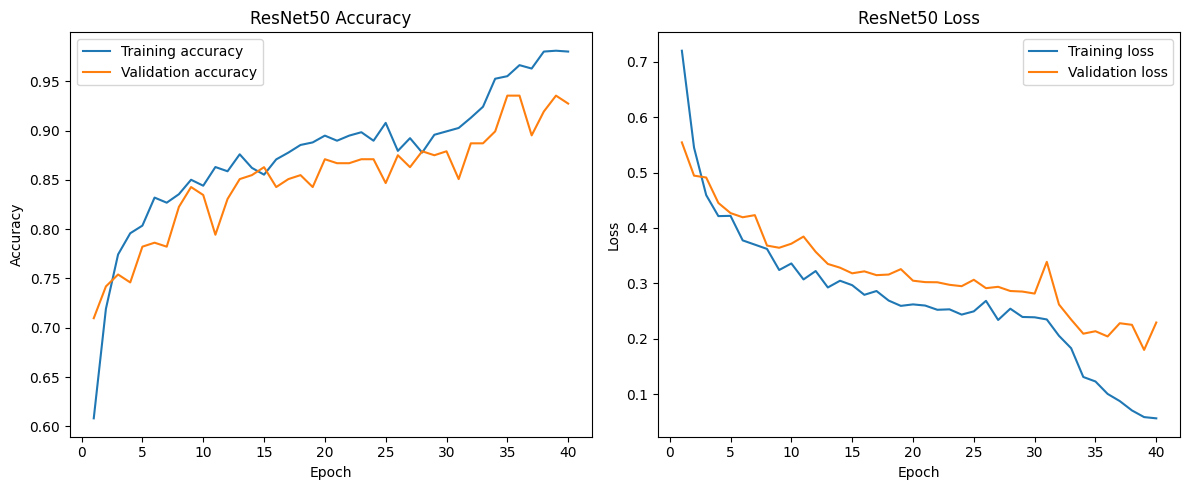

In [27]:
# One figure with 2 plots side by side
plt.figure(figsize=(12, 5))
resnet_accuracy = history_resnet.history["accuracy"] + history_finetune.history["accuracy"]
resnet_val_accuracy = history_resnet.history["val_accuracy"] + history_finetune.history["val_accuracy"]
resnet_loss = history_resnet.history["loss"] + history_finetune.history["loss"]
resnet_val_loss = history_resnet.history["val_loss"] + history_finetune.history["val_loss"]
resnet_epochs = range(1, len(resnet_accuracy) + 1)

# Plot 1: training accuracy vs validation accuracy
plt.subplot(1, 2, 1)
plt.plot(resnet_epochs, resnet_accuracy, label="Training accuracy")
plt.plot(resnet_epochs, resnet_val_accuracy, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()

# Plot 2: traing loss vs validation loss
plt.subplot(1, 2, 2)
plt.plot(resnet_epochs, resnet_loss, label="Training loss")
plt.plot(resnet_epochs, resnet_val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Loss")
plt.legend()

# Make sure labels and titles don't overlap
plt.tight_layout()

# Save the plot for the report
plt.savefig("os.path.join(FIGURES_DIR, "resnet50_accuracy_loss.png")", dpi=300, bbox_inches="tight")

# Show the graph below

## Print the final record results 

In [28]:
# Get the last row from the metrics table.
# The last row represents the final epoch of training.
final_results = metrics_table.iloc[-1]

# Print the final training and validation metrics in a readable format.
print("Final ResNet50 results")
print("Training accuracy:", final_results["accuracy"])
print("Training loss:", final_results["loss"])
print("Training precision:", final_results["precision"])
print("Training recall:", final_results["recall"])
print("Training F1-score:", final_results["f1_score"])
print("Training defective recall:", final_results["defective_recall"])
print("Validation accuracy:", final_results["val_accuracy"])
print("Validation loss:", final_results["val_loss"])
print("Validation precision:", final_results["val_precision"])
print("Validation recall:", final_results["val_recall"])
print("Validation F1-score:", final_results["val_f1_score"])
print("Validation defective recall:", final_results["val_defective_recall"])

Final ResNet50 results
Training accuracy: 0.9801895022392273
Training loss: 0.056185632944107056
Training precision: 0.9810017347335815
Training recall: 0.9793103337287903
Training F1-score: 0.9801552545419571
Training defective recall: 0.97933030128479
Validation accuracy: 0.9274193644523621
Validation loss: 0.2292211651802063
Validation precision: 0.8840579986572266
Validation recall: 0.9838709831237793
Validation F1-score: 0.9312976822953074
Validation defective recall: 0.4358258843421936


## 10. ResNet50 Evaluation on Held-Out Test Set

In [29]:
# y_true will store the true labels from the test data 
y_true = []

# y_pred will store the labels predicted by the trainde model 
y_pred = []

for images, labels in test_ds:

    probabilities = resnet50_model.predict(images)

    #convert predicted probabilites into 1D array with class labels 1 and 0 
    predicted_labels = (probabilities >= 0.5).astype("int32").flatten()

    #adding the real labels to y_true.
    y_true.extend(labels.numpy())

    #adding the predicted labels to y_pred.
    y_pred.extend(predicted_labels)


#Convert lists into numpy arrays so that sklearn can work with them easier 
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# This confirms that we have one prediction for each real label.
print("Class names:", class_names)
print("Number of real labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

#using the sklearn built in confusion matrix 
cm = confusion_matrix(y_true, y_pred)

# Create the classification report.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print("Class names:", class_names)

# Print the confusion matrix.
print(cm)

# Print the classification report.
print(report)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Class names: ['defective', 'non_defective']
Number of real labels: 249
Number of predicted labels: 249
Class names: ['defective', 'non_defective']
[[110  14]
 [  5 120]]
               precision    recall  f1-score   support

    defective       0.96      0.89      0.92       124
non_defective       0.90      0.96      0.93       125

     accuracy                           0.92       249
    macro avg       0.93      0.92      0.92       249
 weighted avg       0.93      0.92      0.92       249



## Save the Evaluation Results of ResNet50 in a file 


In [30]:
report_path = os.path.join(RESULTS_DIR, "resnet50_classification_report.txt")
with open(report_path, "w") as file:
    file.write("Class names: " + str(class_names) + "\n\n")
    file.write("Confusion matrix:\n")
    file.write(str(cm))
    file.write("\n\nClassification report:\n")
    file.write(report)

print(f"Saved ResNet50 evaluation report to {report_path}")

Saved evaluation report to resnet50_classification_report_fixed.txt
